# 01 Problem framing (Part A)

NkwaPay must decide, for each loan application, **whether to lend** and **how much**. This notebook fixes the decision point, the label, which columns may be used, the two task specifications and the cedi cost matrix that sets the approval threshold. Later sections import the outcomes from `src/schema.py` and `src/costs.py`.

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.config import set_seed, TRAIN_CSV, TEST_CSV, FIGURES
from src import schema
from src.costs import LoanEconomics, threshold_vs
set_seed()
pd.set_option("display.max_colwidth", 120)
tr = pd.read_csv(TRAIN_CSV, parse_dates=["disbursement_date", "due_date"])
te = pd.read_csv(TEST_CSV, parse_dates=["disbursement_date", "due_date"])
tr.shape, te.shape

((68654, 16), (18594, 15))

## 1.1 Loan timeline and decision point

The model runs at **approval**: the borrower has picked product, amount and term, and NkwaPay has not yet disbursed. The label only becomes known after the due date, so any column whose value is set or updated after approval cannot be a feature.

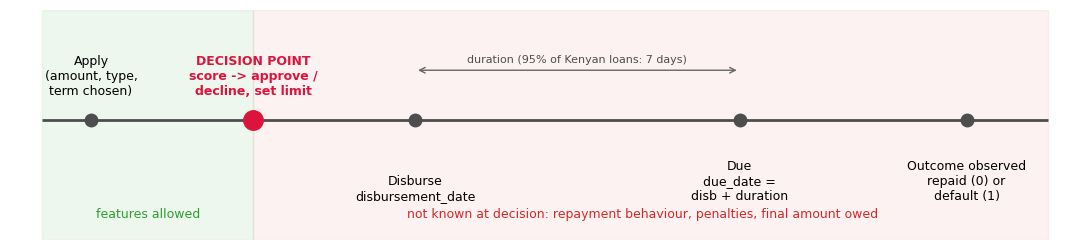

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.6))
events = [(0, "Apply\n(amount, type,\nterm chosen)"), (1, "DECISION POINT\nscore -> approve /\ndecline, set limit"),
          (2, "Disburse\ndisbursement_date"), (4, "Due\ndue_date =\ndisb + duration"), (5.4, "Outcome observed\nrepaid (0) or\ndefault (1)")]
ax.hlines(0, -0.3, 5.9, color="0.3", lw=2)
for x, label in events:
    hot = x == 1
    ax.plot(x, 0, "o", ms=14 if hot else 9, color="crimson" if hot else "0.3")
    ax.annotate(label, (x, 0), xytext=(0, 18 if x not in (2, 4, 5.4) else -58), textcoords="offset points",
                ha="center", fontsize=9, weight="bold" if hot else "normal", color="crimson" if hot else "black")
ax.axvspan(-0.3, 1, color="tab:green", alpha=0.08); ax.axvspan(1, 5.9, color="tab:red", alpha=0.06)
ax.text(0.35, -0.9, "features allowed", ha="center", color="tab:green", fontsize=9)
ax.text(3.4, -0.9, "not known at decision: repayment behaviour, penalties, final amount owed", ha="center", color="tab:red", fontsize=9)
ax.annotate("", xy=(4, 0.45), xytext=(2, 0.45), arrowprops=dict(arrowstyle="<->", color="0.4"))
ax.text(3, 0.52, "duration (95% of Kenyan loans: 7 days)", ha="center", fontsize=8, color="0.3")
ax.set_xlim(-0.5, 6.1); ax.set_ylim(-1.1, 1.0); ax.axis("off")
plt.tight_layout(); plt.savefig(FIGURES / "01_loan_timeline.png", dpi=200); plt.show()

In [3]:
# Facts the timeline relies on
d = (tr.due_date - tr.disbursement_date).dt.days
print("due_date == disbursement_date + duration on", f"{(d == tr.duration).mean():.0%}", "of rows")
print("Train disbursed", tr.disbursement_date.min().date(), "to", tr.disbursement_date.max().date(),
      "| latest due date", tr.due_date.max().date())

due_date == disbursement_date + duration on 100% of rows
Train disbursed 2021-10-04 to 2024-11-14 | latest due date 2025-10-27


**Two consequences for later sections**

- *Borrower history (section 3).* A past loan's outcome is only known after **its due date**, not its disbursement date. History features must join on past `due_date < current disbursement_date`, otherwise a still-running loan's default leaks in.
- *Temporal validation (section 4).* A loan disbursed just before the split can have its due date after it. Train only on loans whose `due_date` precedes the validation window.

## 1.2 Label

`target = 1` means the customer **defaulted**, `0` means they repaid (`VariableDefinitions.txt`). The positive class is the costly one, so recall and precision below are about catching defaulters. The data does not state the default rule (for example days past due or grace period); we record that as an open question for NkwaPay.

In [4]:
lab = tr.target.value_counts().rename(index={0: "repaid (0)", 1: "default (1)"}).to_frame("loans")
lab["share"] = (lab.loans / len(tr)).round(4); lab

,loans,share
target,,
repaid (0),67396,0.9817
default (1),1258,0.0183


In [5]:
# Default rate is not stable over time or across groups, which matters for validation and fairness
pd.concat({
    "by year": tr.groupby(tr.disbursement_date.dt.year).target.agg(["size", "mean"]),
    "by New/Repeat": tr.groupby("New_versus_Repeat").target.agg(["size", "mean"]),
    "by lender": tr.groupby("lender_id").target.agg(["size", "mean"]),
}).rename(columns={"size": "loans", "mean": "default_rate"}).round(4)

loans  default_rate
by year       2021            39        0.5385
              2022         64405        0.0130
              2023          1240        0.1153
              2024          2970        0.0869
by New/Repeat New Loan       567        0.2099
              Repeat Loan  68087        0.0167
by lender     245684         188        0.4149
              251804        3542        0.0892
              267277         271        0.2952
              267278       64653        0.0121

## 1.3 Feature audit

Each column is checked against the decision point. Two columns needed evidence rather than judgement.

### Leakage check: `Total_Amount_to_Repay`

If the amount to repay were fixed by the contract, two loans on the same product, term and lender would have the same repay-to-principal ratio whatever happened later. They do not: on the dominant contract (Type_1, 7 days, lender 267278) repaid loans owe about 0.7% over principal and defaulted loans about 41%. On its own the ratio separates defaulters with AUC 0.99. The most plausible explanation is late penalties added after the due date, so the column (and `Lender_portion_to_be_repaid`, which is derived from it) is treated as **post-outcome leakage** and dropped.

In [6]:
tr["repay_ratio"] = tr.Total_Amount_to_Repay / tr.Total_Amount
same_contract = tr[(tr.loan_type == "Type_1") & (tr.duration == 7) & (tr.lender_id == 267278)]
display(same_contract.groupby("target").repay_ratio.describe(percentiles=[.05, .5, .95]).round(3))

auc = {c: roc_auc_score(tr.target, tr[c]) for c in
       ["Total_Amount", "duration", "Lender_portion_Funded", "Total_Amount_to_Repay", "Lender_portion_to_be_repaid"]}
auc["repay_ratio (derived)"] = roc_auc_score(tr.target, tr.repay_ratio)
auc["repay_ratio, same contract only"] = roc_auc_score(same_contract.target, same_contract.repay_ratio)
pd.Series(auc, name="single-column AUC").round(3).sort_values()

,count,mean,std,min,5%,50%,95%,max
target,,,,,,,,
0,61203.0,1.013,0.027,0.0,1.000,1.007,1.037,1.714
1,520.0,1.411,0.179,1.0,1.125,1.412,1.679,2.181


Lender_portion_Funded              0.477
Total_Amount                       0.618
Total_Amount_to_Repay              0.661
duration                           0.665
Lender_portion_to_be_repaid        0.695
repay_ratio (derived)              0.981
repay_ratio, same contract only    0.991
Name: single-column AUC, dtype: float64

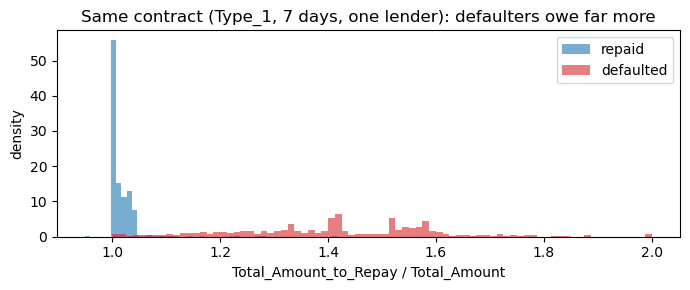

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for t, c in [(0, "tab:blue"), (1, "tab:red")]:
    ax.hist(same_contract.loc[same_contract.target == t, "repay_ratio"].clip(0.95, 2), bins=80,
            density=True, alpha=0.6, color=c, label=["repaid", "defaulted"][t])
ax.set(xlabel="Total_Amount_to_Repay / Total_Amount", ylabel="density",
       title="Same contract (Type_1, 7 days, one lender): defaulters owe far more")
ax.legend(); plt.tight_layout(); plt.savefig(FIGURES / "01_repay_ratio_leakage.png", dpi=200); plt.show()

The same pattern is present in Test (Ghana rows have even more high ratios), so a leaderboard model would score well using it, but it would not exist for a new applicant.

In [8]:
te["repay_ratio"] = te.Total_Amount_to_Repay / te.Total_Amount
(te.assign(over_10pct=te.repay_ratio > 1.10).groupby("country_id").over_10pct.mean()
   .to_frame("share of Test loans owing >10% over principal").round(3))

,share of Test loans owing >10% over principal
country_id,
Ghana,0.118
Kenya,0.026


### Redundancy and structure checks

In [9]:
checks = {
    "ID = 'ID_' + customer_id + tbl_loan_id + lender_id":
        (tr.ID == "ID_" + tr.customer_id.astype(str) + tr.tbl_loan_id.astype(str) + tr.lender_id.astype(str)).mean(),
    "Amount_Funded_By_Lender = Lender_portion_Funded x Total_Amount":
        np.isclose(tr.Amount_Funded_By_Lender, tr.Lender_portion_Funded * tr.Total_Amount, rtol=1e-3).mean(),
    "due_date = disbursement_date + duration": (d == tr.duration).mean(),
    "country_id is Kenya": (tr.country_id == "Kenya").mean(),
}
pd.Series(checks, name="share of rows").round(4)

ID = 'ID_' + customer_id + tbl_loan_id + lender_id                1.0
Amount_Funded_By_Lender = Lender_portion_Funded x Total_Amount    1.0
due_date = disbursement_date + duration                           1.0
country_id is Kenya                                               1.0
Name: share of rows, dtype: float64

In [10]:
per_loan = tr.groupby("tbl_loan_id").agg(rows=("ID", "size"), lenders=("lender_id", "nunique"), labels=("target", "nunique"))
print(f"{(per_loan.rows > 1).sum():,} loans appear on 2 rows (one per co-funding lender);",
      f"{(per_loan.labels > 1).sum()} of them have conflicting labels.")

2,134 loans appear on 2 rows (one per co-funding lender); 2 of them have conflicting labels.


### Audit table

In [11]:
audit = pd.DataFrame([
    ("ID", "dropped", "Row key; concatenation of customer, loan and lender IDs"),
    ("customer_id", "group key", "Not a feature. Groups CV folds and builds borrower history"),
    ("country_id", "metadata", "Constant (Kenya) in Train; used for Ghana analysis and macro join"),
    ("tbl_loan_id", "group key", "Not a feature. 2,134 loans span two lender rows; dedupe or group on it"),
    ("lender_id", "usable", "Known at approval. 4 lenders in Train; 4 of 5 Ghana lenders unseen, needs an unknown level"),
    ("loan_type", "usable", "Product chosen at application. Ghana Type_3/Type_8 unseen, needs an unknown level"),
    ("Total_Amount", "usable (classifier)", "Requested principal. Heavily skewed, log transform. Target of the regression, so not its input"),
    ("Total_Amount_to_Repay", "dropped (leakage)", "Inflated for defaulters on identical contracts; repay/amount AUC 0.98"),
    ("disbursement_date", "usable (derived)", "Approx. application date. Calendar features and time splits only, not raw"),
    ("due_date", "dropped", "Exactly disbursement_date + duration"),
    ("duration", "usable", "Term chosen at application"),
    ("New_versus_Repeat", "usable", "Known from NkwaPay's own records; recomputable from history"),
    ("Amount_Funded_By_Lender", "dropped", "Exactly Lender_portion_Funded x Total_Amount"),
    ("Lender_portion_Funded", "usable, confirm", "Funding split set when the loan is placed; confirm with NkwaPay it is fixed before approval"),
    ("Lender_portion_to_be_repaid", "dropped (leakage)", "Lender_portion_Funded x Total_Amount_to_Repay; inherits leakage"),
    ("target", "target", "1 = default, 0 = repaid; observed after due date"),
], columns=["column", "role", "reason"])
assert set(audit.column) == set(tr.columns) - {"repay_ratio"}
audit.to_csv(FIGURES.parent / "01_feature_audit.csv", index=False)
audit

,column,role,reason
0,ID,dropped,"Row key; concatenation of customer, loan and lender IDs"
1,customer_id,group key,Not a feature. Groups CV folds and builds borrower history
2,country_id,metadata,Constant (Kenya) in Train; used for Ghana analysis and macro join
3,tbl_loan_id,group key,"Not a feature. 2,134 loans span two lender rows; dedupe or group on it"
4,lender_id,usable,"Known at approval. 4 lenders in Train; 4 of 5 Ghana lenders unseen, needs an unknown level"
5,loan_type,usable,"Product chosen at application. Ghana Type_3/Type_8 unseen, needs an unknown level"
6,Total_Amount,usable (classifier),"Requested principal. Heavily skewed, log transform. Target of the regression, so not its input"
7,Total_Amount_to_Repay,dropped (leakage),Inflated for defaulters on identical contracts; repay/amount AUC 0.98
8,disbursement_date,usable (derived),"Approx. application date. Calendar features and time splits only, not raw"
9,due_date,dropped,Exactly disbursement_date + duration


## 1.4 Task specifications

| | Task 2: Classification | Task 1: Regression |
|---|---|---|
| Question | Will this applicant default? | How much can we safely lend this borrower? |
| Unit | One loan (rows merged per `tbl_loan_id`) | One loan |
| Target | `target` (1 = default) | `log1p(Total_Amount)` on **repaid** loans only |
| Inputs | Usable columns + borrower history + calendar + macro | Same, minus anything derived from the amount (`Total_Amount`, ratios over it) |
| Output | P(default), then approve / decline at the 1.5 threshold | Suggested limit in local currency |
| Primary metric | PR-AUC (1.8% positives make ROC-AUC flattering); also F1, precision, recall, Brier | RMSE and MAE on log scale and in currency |
| Baseline | Predict "no one defaults" (accuracy 98.2%, recall 0) | Predict the mean |
| Decision use | Decline when P(default) > threshold | Offer min(requested, predicted limit) to approved applicants |

**Regression target, a choice to agree as a team.** The data only contains amounts that past lenders *chose* to lend, so regressing on all loans would copy the past policy, including loans that defaulted. Training on repaid loans learns "amount borrowers like this have shown they can repay", which matches *how much to lend*. The cost is selection bias: we never see what a declined or capped borrower would have repaid.

In [12]:
repaid = tr[tr.target == 0]
print(f"Regression rows (repaid loans): {len(repaid):,}")
print("Total_Amount on repaid loans:", repaid.Total_Amount.describe(percentiles=[.5, .99]).round(0).to_dict())

Regression rows (repaid loans): 67,396
Total_Amount on repaid loans: {'count': 67396.0, 'mean': 13172.0, 'std': 81800.0, 'min': 2.0, '50%': 5245.0, '99%': 106701.0, 'max': 15000000.0}


## 1.5 Cost matrix in cedis

Our assumptions for a representative Ghana digital loan (all editable in `src/costs.py`):

| Assumption | Value | Basis |
|---|---|---|
| Principal | GHS 500 | Typical small digital loan |
| Fee + interest over term | 8% flat | Directive requires disclosure, no compounding, no cap |
| Funding cost over term | 2% | Cost of capital |
| Operating cost per loan | GHS 5 | MoMo transfer, SMS, KYC check |
| Collection cost per default | GHS 15 | Calls, agent time |
| Recovery after default | 30% of principal | Base case; varied below |

Kenyan amounts in the data are in KES; this matrix is written in cedis for NkwaPay's Ghana launch and does not convert the training data.

In [13]:
e = LoanEconomics()
cm = pd.DataFrame([[e.gain_good, 0.0], [-e.loss_bad, 0.0]],
                  index=["borrower repays", "borrower defaults"], columns=["approve", "decline"])
print(f"G (approve a repayer)  = 500 x (8% - 2%) - 5           = GHS {e.gain_good:.0f}")
print(f"L (approve a defaulter) = 500 x (1 - 30%) + 10 + 5 + 15 = GHS {e.loss_bad:.0f}")
print(f"Threshold p* = G / (G + L) = {e.gain_good:.0f} / {e.gain_good + e.loss_bad:.0f} = {e.threshold:.3f}")
cm.style.format("GHS {:.0f}").set_caption("Value to NkwaPay per application")

G (approve a repayer)  = 500 x (8% - 2%) - 5           = GHS 25
L (approve a defaulter) = 500 x (1 - 30%) + 10 + 5 + 15 = GHS 380
Threshold p* = G / (G + L) = 25 / 405 = 0.062


,approve,decline
borrower repays,GHS 25,GHS 0
borrower defaults,GHS -380,GHS 0


**Derivation.** Approving an applicant with default probability *p* has expected value (1 − p)·G − p·L; declining is worth 0. Approve when (1 − p)·G > p·L, that is when **p < G / (G + L) ≈ 0.062**. One default wipes out the profit of about L / G ≈ 15 good loans. The base default rate (1.8%) is well below the threshold, so most applicants are approved and the model's job is to find the risky minority. This only works if probabilities are calibrated (section 5).

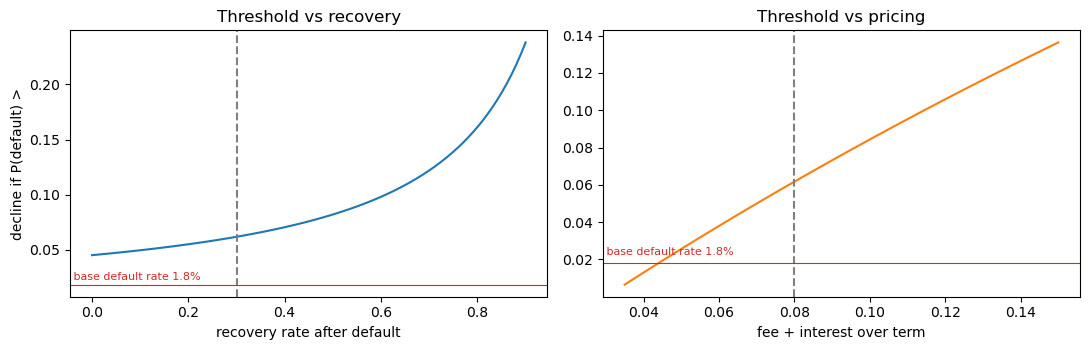

,recovery_rate,loss_bad,threshold
0,0.0,530.0,0.045
1,0.3,380.0,0.062
2,0.5,280.0,0.082
3,0.7,180.0,0.122
4,0.8,130.0,0.161


In [14]:
rec = np.linspace(0, 0.9, 91)
fee = np.linspace(0.035, 0.15, 116)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(rec, threshold_vs("recovery_rate", rec)); axes[0].axvline(e.recovery_rate, ls="--", c="0.5")
axes[0].set(xlabel="recovery rate after default", ylabel="decline if P(default) >", title="Threshold vs recovery")
axes[1].plot(fee, threshold_vs("fee_rate", fee), c="tab:orange"); axes[1].axvline(e.fee_rate, ls="--", c="0.5")
axes[1].set(xlabel="fee + interest over term", title="Threshold vs pricing")
for a in axes: a.axhline(tr.target.mean(), c="tab:red", lw=0.8); a.text(a.get_xlim()[0], tr.target.mean() + .004, " base default rate 1.8%", color="tab:red", fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "01_threshold_sensitivity.png", dpi=200); plt.show()

pd.DataFrame({"recovery_rate": [0, .3, .5, .7, .8]}).assign(
    loss_bad=lambda x: [LoanEconomics(recovery_rate=r).loss_bad for r in x.recovery_rate],
    threshold=lambda x: threshold_vs("recovery_rate", x.recovery_rate).round(3))

**How the threshold moves.** With no recovery the threshold falls to 4.5%; at 80% recovery it rises to 16%, so NkwaPay can afford to approve riskier borrowers. Pricing matters even more: at a 3% fee (1% over funding cost, which only covers the GHS 5 operating cost) the gain on a good loan is zero and no loan is worth making; below about 4.5% the threshold drops under the 1.8% base rate, so NkwaPay would have to decline the typical applicant. The Kenyan contracts in the data charge about 1% over 7 days, which shows how thin the margin can be. Section 5 sweeps the classifier threshold against this matrix and reports the expected GHS value at each operating point.

## Open questions for NkwaPay
1. What is the default rule (days past due, grace period)?
2. Is `Total_Amount_to_Repay` updated after disbursement (penalties)? Our evidence says yes.
3. Is the lender funding split fixed before approval?
4. Real fee, recovery and collection figures for Ghana, to replace our assumptions.